<a href="https://colab.research.google.com/github/Andre-Gomez-Serrano/Actividad-4-EDA/blob/main/Actividad4EDA_A01733624.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Carlos André Gómez Serrano
*   MATRÍCULA: A01733624

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [ ]:
#Descarga el archivo: personal_loan.csv y guarda, en un dataframe (loan_df), todos sus registros.
loan_df=pd.read_csv('personal_loan.csv')

In [ ]:
#Haz que la columna ID sea el índice del dataframe.
loan_df.set_index('ID',inplace=True)

In [ ]:
#Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [ ]:
#Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
loan_df.describe()


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [ ]:
#Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
loan_df[loan_df['Age']>100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [ ]:
#Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
# Registros iniciales
print("Registros iniciales:", len(loan_df))

# Eliminación de registros inválidos (cada regla con su justificación)

# Age: 123, 130 y 144 años son imposibles (el resto llega a 67)
loan_df = loan_df[(loan_df['Age'] >= 18) & (loan_df['Age'] <= 100)]

# Experience: los años de experiencia no pueden ser negativos (-1, -2, -3)
loan_df = loan_df[loan_df['Experience'] >= 0]

# Family: un hogar no puede tener 0 o menos integrantes (-1, -3)
loan_df = loan_df[loan_df['Family'] > 0]

# Education: solo existen las categorías 1, 2 y 3 (el 7.3 es inválido)
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]

# ZIP Code: los códigos postales de EE. UU. tienen 5 dígitos (9307 tiene 4)
loan_df = loan_df[loan_df['ZIP Code'].astype(str).str.len() == 5]

print("Registros finales:", len(loan_df))   # 4977 (se eliminaron 60)

# Columnas Sí/No: no hay valores inválidos, solo notación mezclada (Yes/No y 1/0).
# No se eliminan registros (se perdería el 96.8% de los datos); se unifica a 1/0.
mapa = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
for col in ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']:
    loan_df[col] = loan_df[col].astype(str).map(mapa)

loan_df['Education'] = loan_df['Education'].astype(int)

Registros iniciales: 5037
Registros finales: 4977


In [ ]:
#¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?
n_inicial = 5037   # o len(loan_df) antes de eliminar registros
n_final = len(loan_df)
eliminados = n_inicial - n_final
porcentaje = eliminados / n_inicial * 100

print(f"Registros eliminados: {eliminados}")
print(f"Porcentaje respecto al total inicial: {porcentaje:.2f}%")

Registros eliminados: 60
Porcentaje respecto al total inicial: 1.19%


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [ ]:
#Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
raw = pd.read_csv('personal_loan.csv').set_index('ID')
cols_texto = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
texto_df = raw.loc[loan_df.index, cols_texto]

display(texto_df.describe())

for col in cols_texto:
    print(f"\n{col}")
    print(texto_df[col].value_counts())


,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3454,2674,2427,1684,2608



Personal Loan
Personal Loan
0      3454
No     1010
Yes     360
1       117
Name: count, dtype: int64

Securities Account
Securities Account
No     2674
0      1748
Yes     391
1       128
Name: count, dtype: int64

CD Account
CD Account
No     2427
0      2215
1       160
Yes     139
Name: count, dtype: int64

Online
Online
Yes    1684
No     1624
1      1263
0       370
Name: count, dtype: int64

CreditCard
CreditCard
0      2608
Yes     897
No      889
1       547
Name: count, dtype: int64


In [ ]:
#Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.
cols_bin = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

# Yes/1 -> 1 y No/0 -> 0
mapa = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
for col in cols_bin:
    loan_df[col] = loan_df[col].astype(str).map(mapa)

# Verificación: solo 0 y 1, sin nulos
for col in cols_bin:
    print(col, sorted(loan_df[col].unique()), "| nulos:", loan_df[col].isna().sum())
    print(loan_df[col].value_counts(), "\n")

Personal Loan [np.int64(0), np.int64(1)] | nulos: 0
Personal Loan
0    4462
1     479
Name: count, dtype: int64 

Securities Account [np.int64(0), np.int64(1)] | nulos: 0
Securities Account
0    4426
1     515
Name: count, dtype: int64 

CD Account [np.int64(0), np.int64(1)] | nulos: 0
CD Account
0    4640
1     301
Name: count, dtype: int64 

Online [np.int64(0), np.int64(1)] | nulos: 0
Online
1    2951
0    1990
Name: count, dtype: int64 

CreditCard [np.int64(0), np.int64(1)] | nulos: 0
CreditCard
0    3489
1    1452
Name: count, dtype: int64 



4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [ ]:
# 4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
# Asegúrate de reiniciar el índice para mantener una secuencia continua.

# Verificar cantidad de registros duplicados
duplicados = loan_df.duplicated().sum()
print(f"Registros duplicados detectados: {duplicados}")

if duplicados > 0:
    loan_df = loan_df.drop_duplicates()
    print(f"Registros duplicados eliminados. Registros restantes: {len(loan_df)}")

# Reiniciar el índice para asegurar una secuencia continua
loan_df = loan_df.reset_index(drop=True)
print("Índice reiniciado exitosamente.")

Registros duplicados detectados: 36
Registros duplicados eliminados. Registros restantes: 4941
Índice reiniciado exitosamente.


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [ ]:
#CONVERSIONES:

# Nominal: ZIP Code -> object (identificador, se guarda como texto)
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str).astype('object')

# Ordinal: Education -> category con orden 1 < 2 < 3
loan_df['Education'] = loan_df['Education'].astype(
    pd.CategoricalDtype(categories=[1, 2, 3], ordered=True)
)

# Binarias -> category
cols_bin = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
for col in cols_bin:
    loan_df[col] = loan_df[col].astype('category')

# Verificación
print(loan_df.dtypes)
print(loan_df['Education'].cat.ordered, loan_df['Education'].cat.categories.tolist())

Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object
True [1, 2, 3]


In [ ]:
#Crea dos listas llamadas num_cols y cat_cols que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

Numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [ ]:
#Estadísticas descriptivas incluyendo los valores de simetría y curtosis.
desc = loan_df[num_cols].describe().T
desc['skew'] = loan_df[num_cols].skew()        # asimetría
desc['kurtosis'] = loan_df[num_cols].kurt()    # curtosis en exceso (normal = 0)
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.560,11.316,24.0,36.0,46.0,55.0,67.0,-0.023,-1.162
Experience,4941.0,20.335,11.308,0.0,11.0,20.0,30.0,43.0,-0.015,-1.135
Income,4941.0,73.827,46.107,8.0,39.0,64.0,98.0,224.0,0.842,-0.046
Family,4941.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.159,-1.404
CCAvg,4941.0,1.936,1.748,0.0,0.7,1.5,2.6,10.0,1.595,2.636
Mortgage,4941.0,56.664,101.875,0.0,0.0,0.0,101.0,635.0,2.104,4.760


In [ ]:
#Clasificación de las variables Age, Income y Mortgage según los valores observados de asimetría y curtosis:

def clasificar(serie):
    sk, ku = serie.skew(), serie.kurt()
    if abs(sk) < 0.5:
        asim = "simétrica"
    elif abs(sk) <= 1:
        asim = "asimetría " + ("positiva" if sk > 0 else "negativa") + " moderada"
    else:
        asim = "asimetría " + ("positiva" if sk > 0 else "negativa") + " fuerte"

    if abs(ku) < 0.5:
        curt = "mesocúrtica"
    elif ku < 0:
        curt = "platicúrtica"
    else:
        curt = "leptocúrtica"
    return sk, ku, asim, curt

for col in ['Age', 'Income', 'Mortgage']:
    sk, ku, asim, curt = clasificar(loan_df[col])
    print(f"{col}: asimetría = {sk:.2f}, curtosis = {ku:.2f} -> {asim}, {curt}")

Age: asimetría = -0.02, curtosis = -1.16 -> simétrica, platicúrtica
Income: asimetría = 0.84, curtosis = -0.05 -> asimetría positiva moderada, mesocúrtica
Mortgage: asimetría = 2.10, curtosis = 4.76 -> asimetría positiva fuerte, leptocúrtica


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

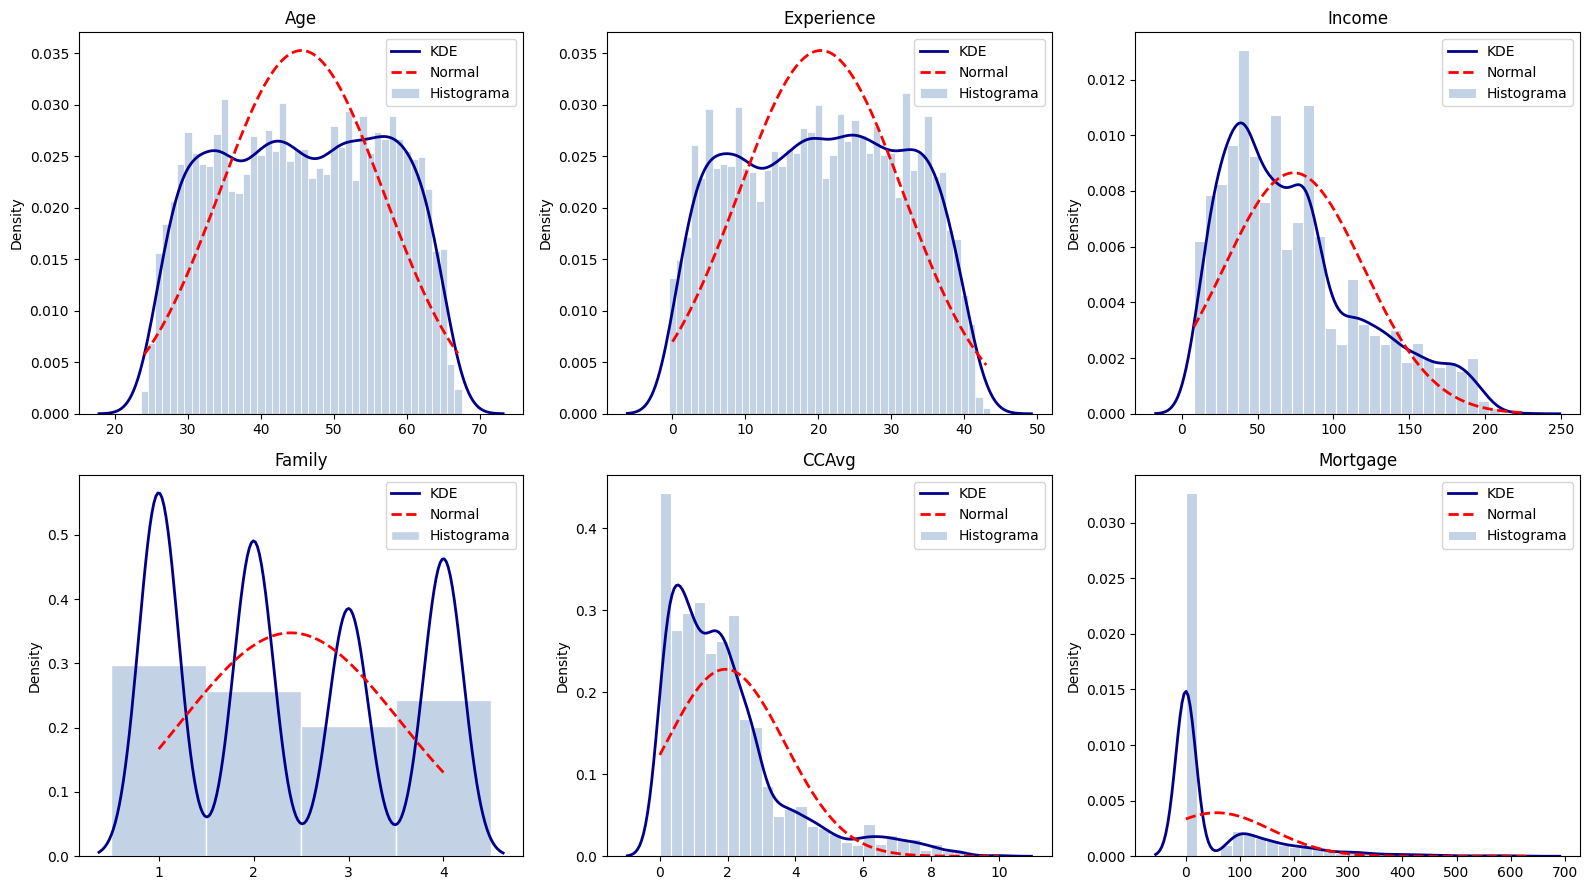

In [ ]:
#histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    datos = loan_df[col]

    # Histograma en densidad (para poder compararlo con la KDE y la normal)
    if datos.nunique() <= 60:   # pocos valores enteros distintos (Age, Experience, Family)
        sns.histplot(datos, stat='density', discrete=True, color='lightsteelblue',
                     edgecolor='white', ax=ax, label='Histograma')
    else:
        sns.histplot(datos, stat='density', bins=30, color='lightsteelblue',
                     edgecolor='white', ax=ax, label='Histograma')

    # Curva KDE
    sns.kdeplot(datos, color='darkblue', linewidth=2, ax=ax, label='KDE')

    # Normal de referencia con la media y desviación de la variable
    mu, sigma = datos.mean(), datos.std()
    x = np.linspace(datos.min(), datos.max(), 300)
    ax.plot(x, norm.pdf(x, mu, sigma), color='red', linestyle='--', linewidth=2, label='Normal')

    ax.set_title(col)
    ax.set_xlabel('')
    ax.legend()

plt.tight_layout()
plt.show()

**Age**: las medidas numéricas y la forma coinciden. Una asimetría cercana a 0 y una curtosis negativa son justo lo que produce una distribución casi uniforme. Las barras caen en los extremos (24 y 67) porque el rango es acotado, y por eso la KDE se ve algo achatada.

**Income**: la asimetría positiva se ve claramente, y la media (73.8) queda por encima de la mediana (64). La curtosis cercana a 0 significa que las colas no son excepcionalmente pesadas, pero no implica que se parezca a una normal: el histograma tiene el pico a la izquierda y una cola a la derecha, y la normal es simétrica. Por eso la curtosis sola no basta, y hay que leerla junto con la asimetría.

**Mortgage**: los números anticipan una distribución extrema y el histograma lo confirma. Además, el gráfico revela algo que los dos valores no muestran: el 69% de los registros vale exactamente 0, así que hay una acumulación en un solo punto y luego un grupo pequeño con hipotecas positivas. La media (56.7) es mucho mayor que la mediana (0), y por eso la normal de referencia asigna densidad incluso a valores negativos, que no existen.

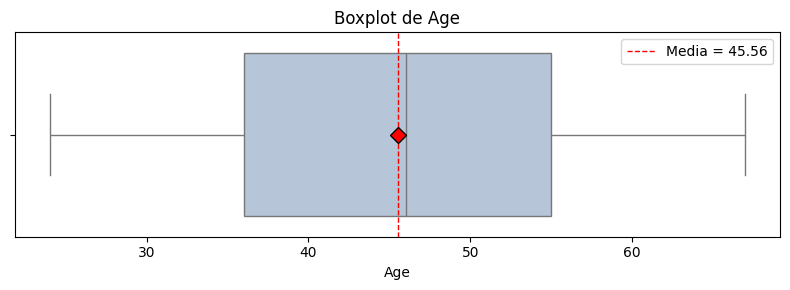

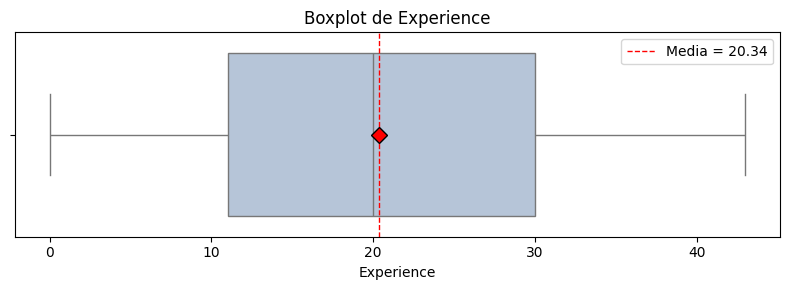

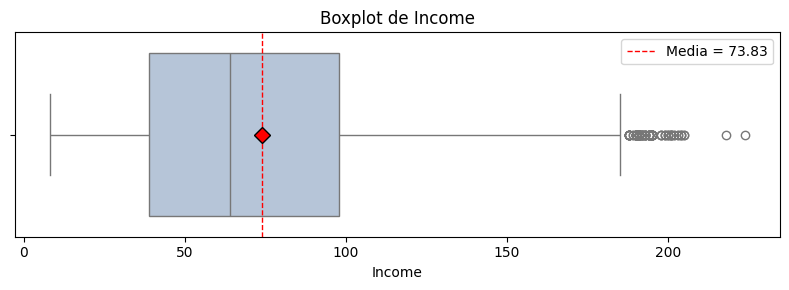

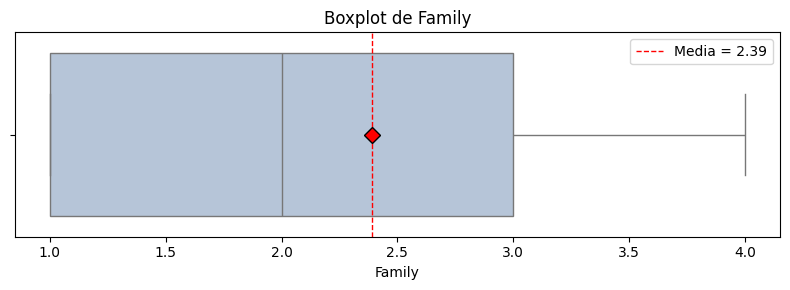

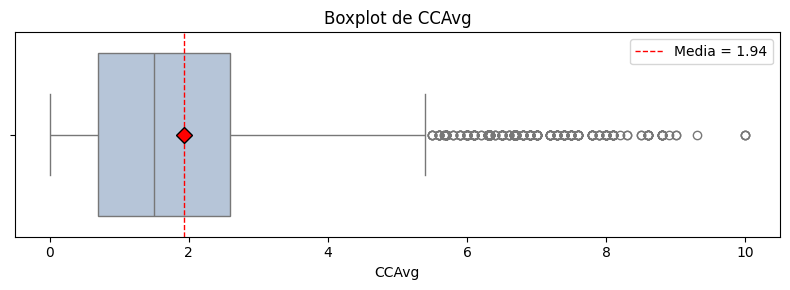

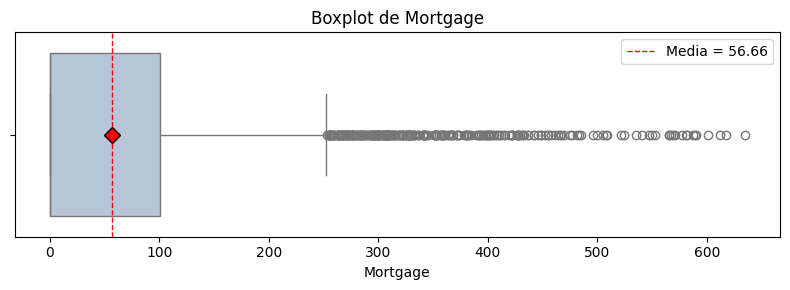

In [ ]:
#gráfico de boxplot individual que incluya la media.
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=loan_df[col], color='lightsteelblue', showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red',
                           'markeredgecolor': 'black', 'markersize': 8})
    media = loan_df[col].mean()
    plt.axvline(media, color='red', linestyle='--', linewidth=1, label=f'Media = {media:.2f}')
    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

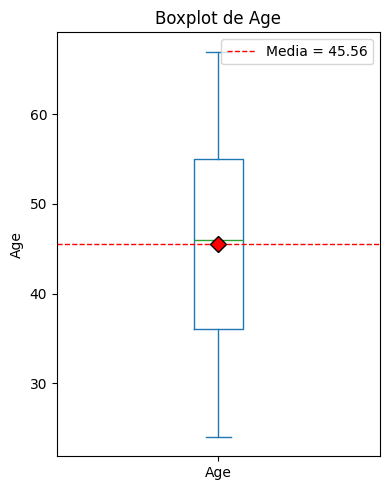

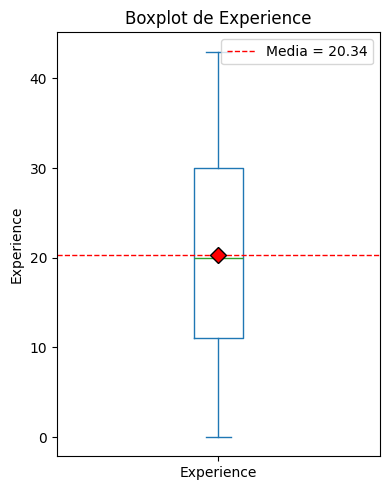

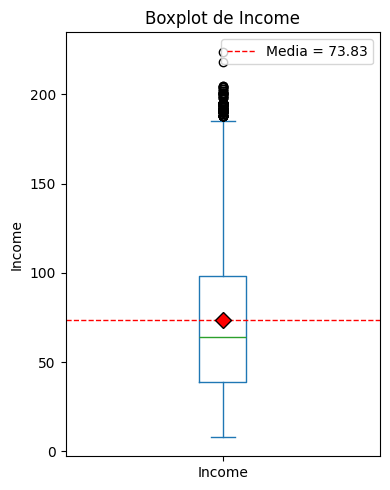

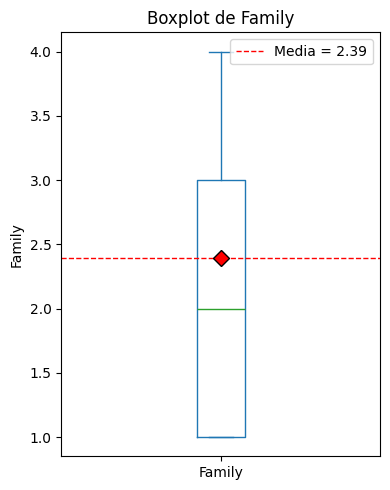

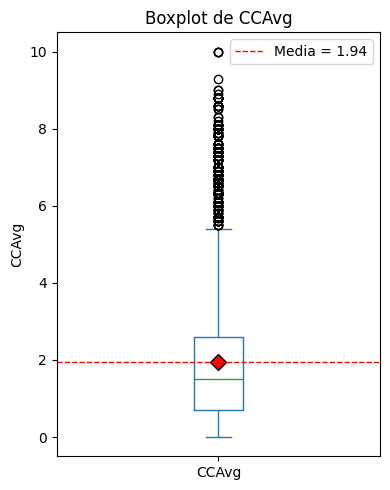

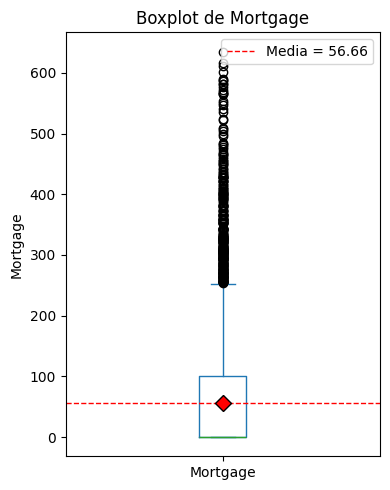

In [ ]:


for col in num_cols:
    # pandas dibuja el boxplot y marca la media con showmeans=True
    ax = loan_df[col].plot(kind='box', showmeans=True, figsize=(4, 5),
                           meanprops={'marker': 'D', 'markerfacecolor': 'red',
                                      'markeredgecolor': 'black', 'markersize': 8})
    # línea de referencia de la media
    media = loan_df[col].mean()
    ax.axhline(media, color='red', linestyle='--', linewidth=1, label=f'Media = {media:.2f}')
    ax.set_title(f'Boxplot de {col}')
    ax.set_ylabel(col)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

In [ ]:
#Análisis de la posición de la media respecto a la mediana
comparacion = pd.DataFrame({
    'media': loan_df[num_cols].mean(),
    'mediana': loan_df[num_cols].median()
})
comparacion['media - mediana'] = comparacion['media'] - comparacion['mediana']
comparacion['asimetría'] = loan_df[num_cols].skew()
comparacion.round(2)

,media,mediana,media - mediana,asimetría
Age,45.56,46.0,-0.44,-0.02
Experience,20.34,20.0,0.34,-0.02
Income,73.83,64.0,9.83,0.84
Family,2.39,2.0,0.39,0.16
CCAvg,1.94,1.5,0.44,1.59
Mortgage,56.66,0.0,56.66,2.10


**Age y Experience**: media y mediana difieren menos de medio año, y la asimetría es casi 0. Las distribuciones son simétricas, lo que coincide con los boxplots, donde la media cae casi sobre la línea de la mediana.

**Income, CCAvg y Mortgage**: la media queda por encima de la mediana, y eso indica cola a la derecha. Unos pocos clientes con ingresos, gastos o hipotecas muy altos jalan la media hacia arriba. En Mortgage el efecto es extremo: la mediana es 0 porque más de la mitad de los clientes no tiene hipoteca, pero la media es 56.66 por los pocos que sí la tienen.

**Coherencia con la asimetría calculada**: mientras más separada está la media de la mediana (en proporción a la desviación estándar), mayor es el valor de asimetría. El orden es Mortgage > CCAvg > Income, el mismo que en la columna de asimetría.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [ ]:
#estadísticas descriptivas de las variables categóricas
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


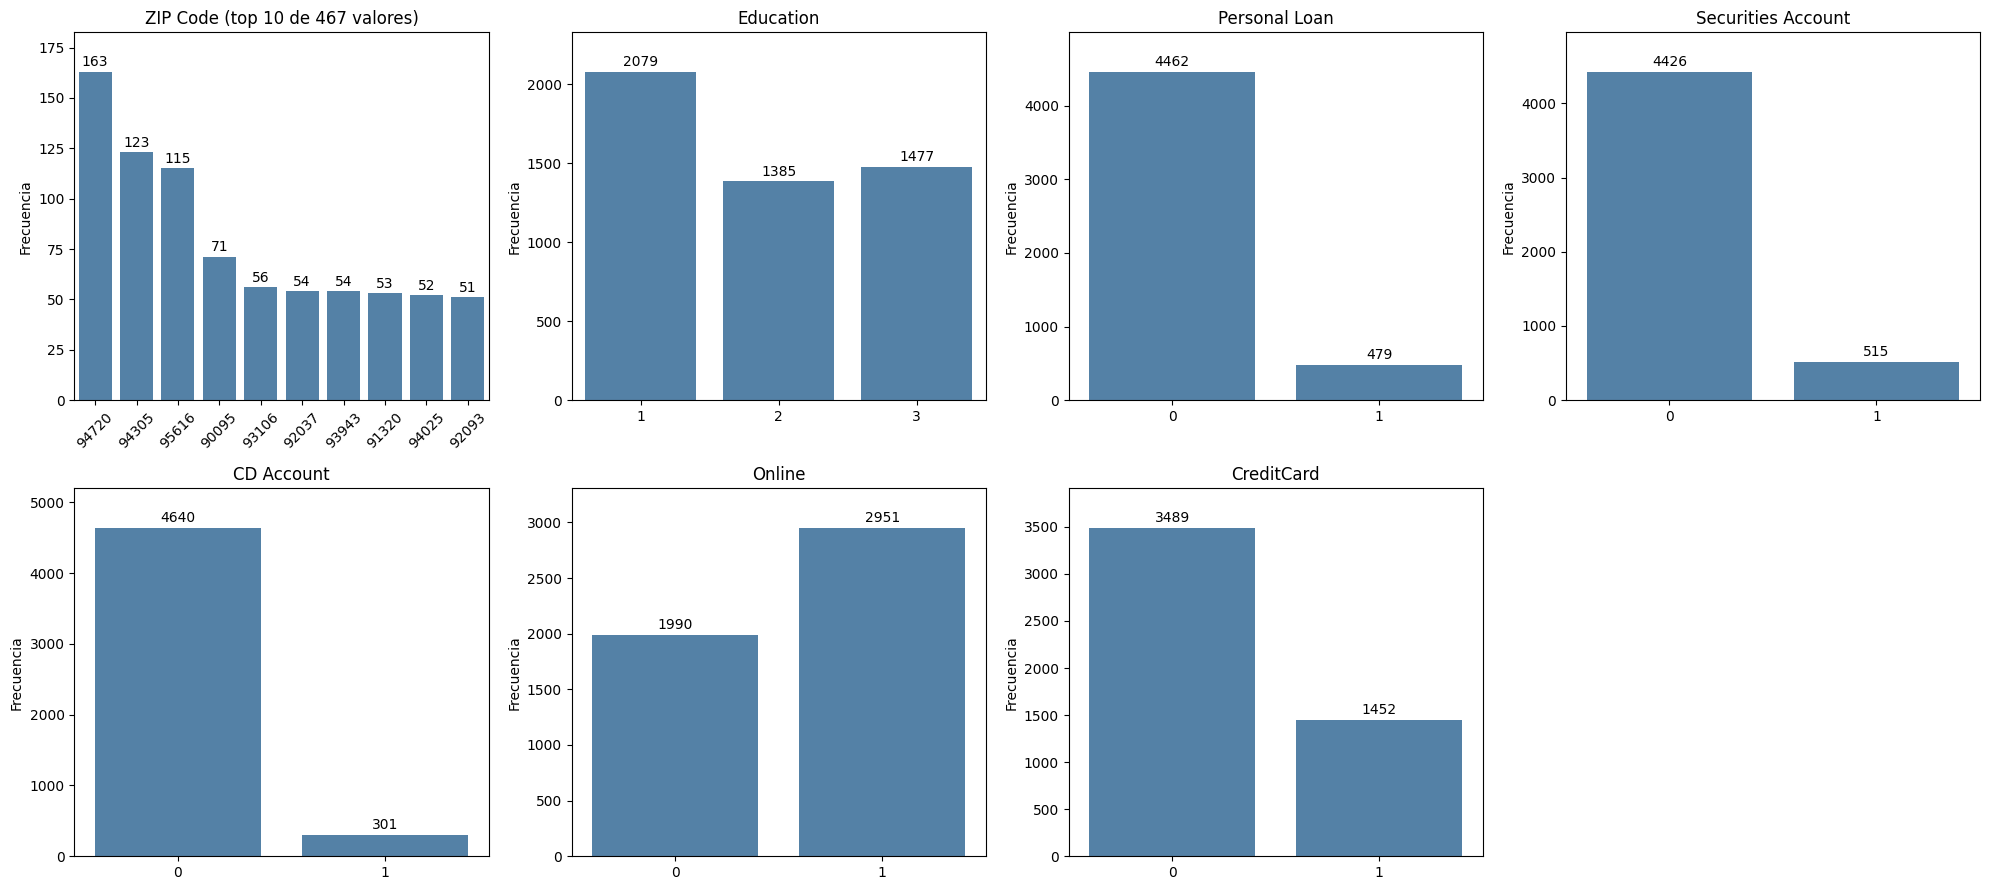

In [ ]:
#gráfico de barras para cada variable.

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    if loan_df[col].nunique() > 10:
        # alta cardinalidad: solo los 10 valores más frecuentes
        orden = loan_df[col].value_counts().head(10).index
        titulo = f'{col} (top 10 de {loan_df[col].nunique()} valores)'
    else:
        # baja cardinalidad: todas las categorías en su orden natural
        orden = sorted(loan_df[col].unique())
        titulo = col

    sns.countplot(x=loan_df[col], order=orden, color='steelblue', ax=ax)
    ax.bar_label(ax.containers[0], padding=2)   # frecuencia sobre cada barra
    ax.margins(y=0.12)
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')
    if loan_df[col].nunique() > 10:
        ax.tick_params(axis='x', rotation=45)

# ocultar el panel sobrante (hay 7 variables y 8 paneles)
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

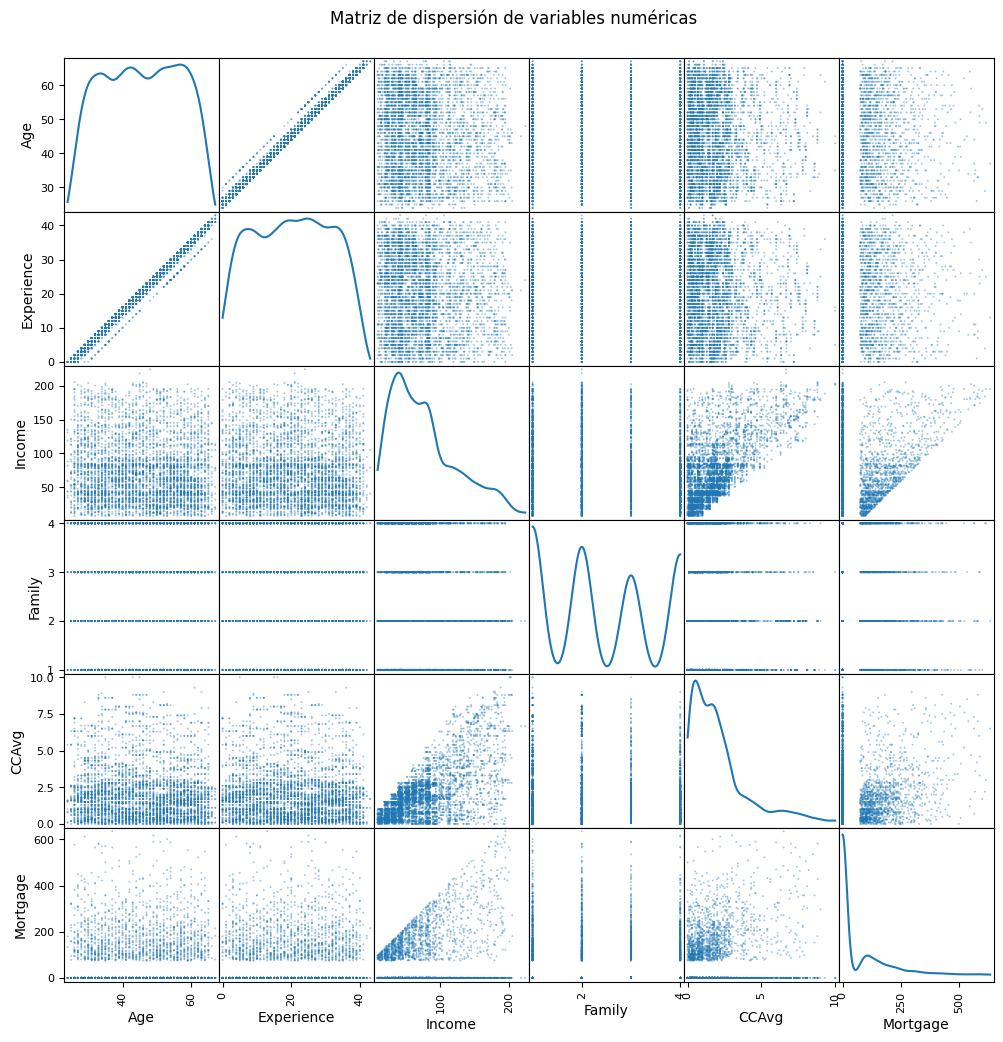

In [ ]:
#matriz de gráficos de dispersión (scatter matrix) de todas las variables numéricas.

pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(12, 12),
                           diagonal='kde', alpha=0.4, s=8)
plt.suptitle('Matriz de dispersión de variables numéricas', y=0.92)
plt.show()

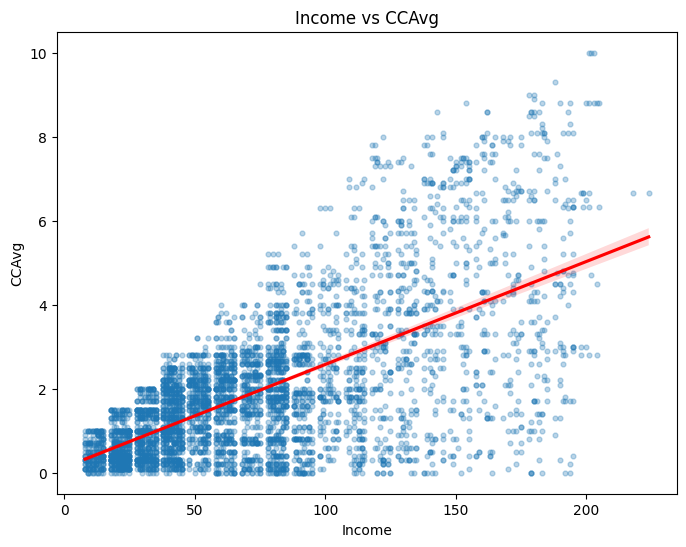

0.65


In [ ]:
#Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.

plt.figure(figsize=(8, 6))
sns.regplot(data=loan_df, x='Income', y='CCAvg',
            scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'})
plt.title('Income vs CCAvg')
plt.show()

print(loan_df['Income'].corr(loan_df['CCAvg']).round(2))   # ≈ 0.65

Se trabajó con Income y CCAvg. Age y Experience tienen una correlación mayor (0.99), pero es casi una identidad, porque la experiencia es la edad menos unos 20 años y no aporta información nueva. Income y CCAvg son el par más informativo, con una relación clara pero no perfecta.

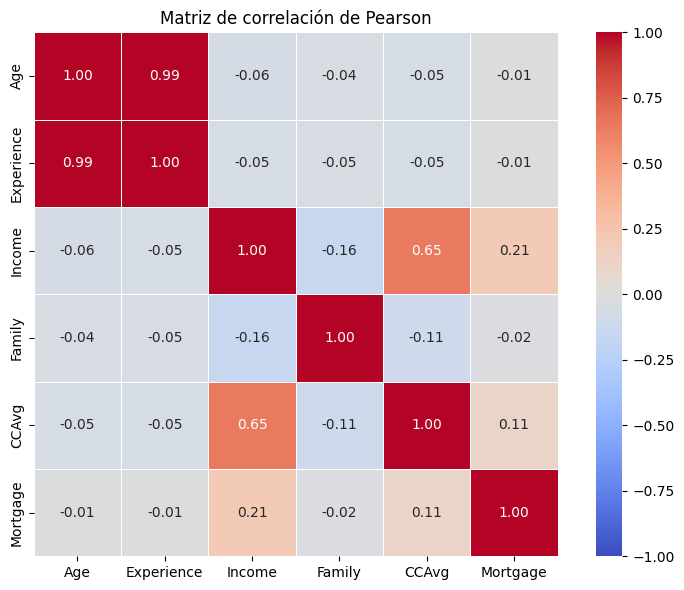

In [ ]:
#Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de Pearson. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

corr = loan_df[num_cols].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Matriz de correlación de Pearson')
plt.tight_layout()
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


Tasa global de aceptación: 9.7 %
Personal Loan          0       1
Age        mean    45.61   45.08
           median  46.00   45.00
Experience mean    20.39   19.86
           median  20.00   20.00
Income     mean    66.22  144.71
           median  59.00  142.00
Family     mean     2.37    2.62
           median   2.00    3.00
CCAvg      mean     1.72    3.90
           median   1.40    3.80
Mortgage   mean    51.90  101.06
           median   0.00    0.00
     variable  correlacion        p_valor
0         Age       -0.014   3.270910e-01
1  Experience       -0.014   3.338768e-01
2      Income        0.504  6.693280e-203
3      Family        0.064   5.891528e-06
4       CCAvg        0.369  5.877093e-109
5    Mortgage        0.143   7.639188e-06


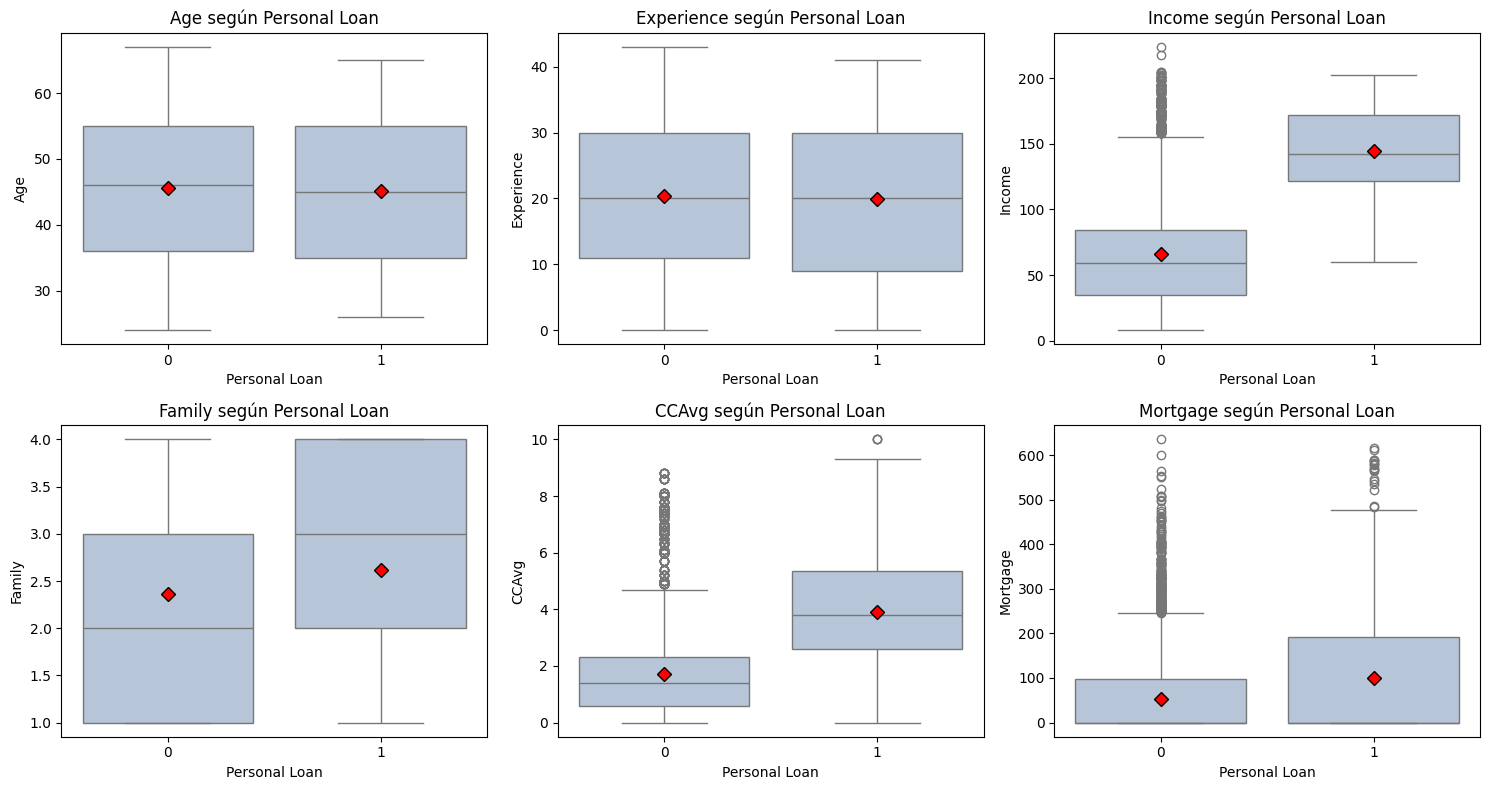

In [ ]:
#VARIABLES NUMÉRICAS

from scipy import stats
y = loan_df['Personal Loan'].astype(int)
print("Tasa global de aceptación:", round(y.mean() * 100, 1), "%")   # ≈ 9.7%

# 1) Numéricas: media y mediana según Personal Loan (0 = no, 1 = sí)
print(loan_df.groupby('Personal Loan', observed=True)[num_cols].agg(['mean', 'median']).T.round(2))

# Fuerza de la relación: correlación con el objetivo y prueba de Mann-Whitney
filas = []
for col in num_cols:
    r = loan_df[col].corr(y)
    p = stats.mannwhitneyu(loan_df.loc[y == 1, col], loan_df.loc[y == 0, col]).pvalue
    filas.append([col, round(r, 3), p])
print(pd.DataFrame(filas, columns=['variable', 'correlacion', 'p_valor']))

# Boxplots por grupo
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=y, y=loan_df[col], ax=ax, color='lightsteelblue', showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red',
                           'markeredgecolor': 'black', 'markersize': 7})
    ax.set_title(f'{col} según Personal Loan')
    ax.set_xlabel('Personal Loan')
plt.tight_layout()
plt.show()

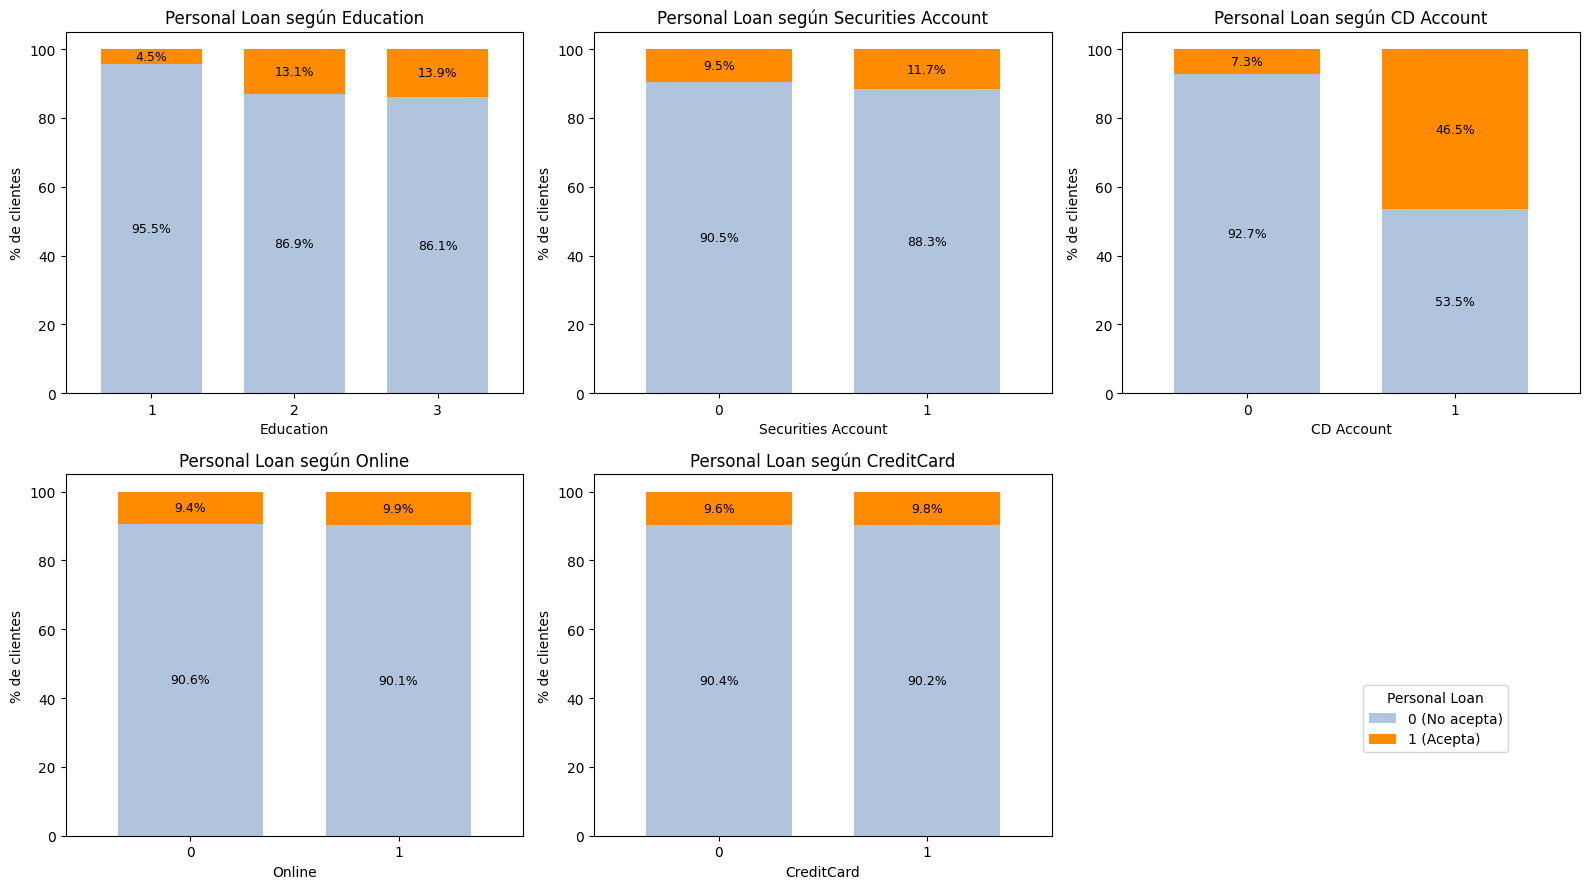

In [ ]:
#VARIABLES CATEGÓRICAS

# Variables categóricas a comparar (sin ZIP Code ni la variable de salida)
cols_plot = ['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

# Unifica Yes/No/1/0 -> 0/1 sin modificar loan_df (funciona aunque ya esté convertido)
mapa = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
def a_binario(serie):
    return serie.astype(str).map(mapa)

y = a_binario(loan_df['Personal Loan'])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, cols_plot):
    x = loan_df[col] if col == 'Education' else a_binario(loan_df[col])
    # % de Personal Loan (0 y 1) dentro de cada categoría: cada barra suma 100%
    prop = pd.crosstab(x, y, normalize='index') * 100
    prop.plot(kind='bar', stacked=True, ax=ax,
              color=['lightsteelblue', 'darkorange'], width=0.7, legend=False)
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.1f%%', label_type='center', fontsize=9)
    ax.set_title(f'Personal Loan según {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('% de clientes')
    ax.tick_params(axis='x', rotation=0)

# Ocultar el panel sobrante (5 variables, 6 paneles)
for ax in axes[len(cols_plot):]:
    ax.set_visible(False)

# Una sola leyenda para toda la figura
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, ['0 (No acepta)', '1 (Acepta)'], title='Personal Loan',
           loc='lower right', bbox_to_anchor=(0.95, 0.15))

plt.tight_layout()
plt.show()

#Hallazgos relevantes

**Variables numéricas:** Income es la variable que mejor distingue a los clientes que aceptan el préstamo: su mediana es de 142 frente a 59 en quienes no lo aceptan, y casi no hay traslape entre ambos grupos. CCAvg sigue un patrón similar, aunque en parte refleja el efecto del ingreso, ya que ambas variables están correlacionadas (r = 0.65). Age y Experience presentan distribuciones prácticamente idénticas en los dos grupos, por lo que no aportan capacidad discriminatoria.

**Variables categóricas:** CD Account muestra la asociación más fuerte con Personal Loan: acepta el préstamo el 46.5% de los clientes que poseen certificado de depósito, frente al 7.3% de quienes no lo tienen. Education también presenta diferencias (4.5% en el nivel 1 contra 13–14% en los niveles 2 y 3). Por el contrario, Online, CreditCard y Securities Account mantienen proporciones similares entre sus categorías (9.4%–11.7%) y no distinguen a quienes aceptan.

**Conclusión:** El perfil del cliente con mayor propensión a aceptar el préstamo se caracteriza por ingresos altos, mayor gasto con tarjeta y posesión de un certificado de depósito. Estos resultados indican asociación, no causalidad.

**Declaración de uso de IA**

Anthropic. (2026). Claude (Claude Sonnet 5.5) [Modelo de lenguaje de gran tamaño]. Utilizado para generación, depuración y verificación de código. https://claude.ai